# CIE 2 – Activity 1: Dataset Preparation Activity
**Unit I – Foundations & Data Preparation | 5 Marks | Online**

## 1. Objective
Inspect a tabular dataset, identify data-quality issues, perform exploratory data analysis (EDA), clean the data, encode categorical features, scale suitable numerical features and save a prepared CSV. **No prediction model is built**, as required by the activity.

## 2. Dataset selection and provenance
- **Dataset:** Student Learning Habits and Academic Performance (synthetic educational dataset)
- **File:** `data/student_learning_habits_raw.csv`
- **Rows / columns:** generated locally; exact dimensions are printed below.
- **Source/provenance:** This is a reproducible synthetic dataset generated specifically for this practical. It is not a downloaded real-student record and contains no personal information. The generation process uses a fixed random seed (`2026`) so the same records can be recreated.
- **Why suitable:** It contains numerical and categorical columns, missing values, duplicate rows, inconsistent category labels and one invalid study-hours value. It therefore supports the cleaning, EDA, encoding and scaling tasks in the activity.
- **Important academic note:** The activity instructions prefer a reliable open-source or academic dataset. This synthetic dataset is transparently identified rather than misrepresented as an external source. If faculty requires an externally sourced dataset, replace the raw CSV with a properly cited public dataset while retaining the same workflow.

### Problem statement
Prepare a clean, analysis-ready student learning-habits dataset while preserving the original CSV. Examine the data, document missingness and inconsistencies, perform basic EDA and save a separate prepared CSV.

## 3. Import libraries and set local file paths
All data is read from the CSV included in this activity folder. No GitHub URL, API, cloud dataset loader or external download is used.

In [1]:
%pip install seaborn

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

DATA_PATH = Path("data/student_learning_habits_raw.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

df_original = pd.read_csv(DATA_PATH)
df = df_original.copy(deep=True)

print("Dataset loaded successfully.")
print("Original shape:", df.shape)

Dataset loaded successfully.
Original shape: (522, 9)


## 4. Step 1 – Select and document the dataset
The dataset represents fictional students and their learning habits. Each row is one synthetic student record.

| Column | Meaning | Type / role |
|---|---|---|
| `student_id` | Synthetic record identifier | Identifier; not a model feature |
| `study_hours_per_day` | Average daily study time | Numerical |
| `attendance_percentage` | Attendance percentage | Numerical |
| `sleep_hours` | Average daily sleep | Numerical |
| `assignments_completed` | Number of assignments completed | Numerical count |
| `internet_access` | Whether internet access is available | Categorical nominal |
| `preferred_study_method` | Preferred learning method | Categorical nominal |
| `parent_education` | Parent/guardian education category | Categorical nominal |
| `final_exam_score` | Final examination score out of 100 | Numerical; possible future target |

The final score is a possible future target for a separate supervised-learning exercise, but this activity does not train a model.

In [3]:
print("First five records:")
display(df.head())
print("\nLast five records:")
display(df.tail())
print("\nDataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()

First five records:


,student_id,study_hours_per_day,attendance_percentage,sleep_hours,assignments_completed,internet_access,preferred_study_method,parent_education,final_exam_score
0,STU1001,2.33,92.2,6.9,7,yes,self study,Graduate,76.0
1,STU1002,3.72,77.9,7.9,6,yes,self study,Graduate,66.2
2,STU1003,0.84,99.9,6.7,5,YES,Group study,School,53.5
3,STU1004,5.28,84.4,6.1,10,YES,Group study,School,76.4
4,STU1005,4.26,87.9,8.0,6,Yes,Self Study,NaN,72.2



Last five records:


,student_id,study_hours_per_day,attendance_percentage,sleep_hours,assignments_completed,internet_access,preferred_study_method,parent_education,final_exam_score
517,STU1518,3.97,93.9,7.3,5,Yes,Group Study,Graduate,83.4
518,STU1519,4.96,69.7,5.7,10,Yes,Self Study,Graduate,76.2
519,STU1520,3.08,73.9,7.4,7,No,Self Study,Postgraduate,75.9
520,STU1016,2.57,84.9,7.0,6,Yes,Self Study,Postgraduate,61.8
521,STU1029,1.74,67.0,7.3,6,Yes,Group Study,School,53.6



Dataset dimensions: (522, 9)

Column names:
['student_id', 'study_hours_per_day', 'attendance_percentage', 'sleep_hours', 'assignments_completed', 'internet_access', 'preferred_study_method', 'parent_education', 'final_exam_score']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 522 entries, 0 to 521
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   student_id              522 non-null    str    
 1   study_hours_per_day     504 non-null    float64
 2   attendance_percentage   509 non-null    float64
 3   sleep_hours             507 non-null    float64
 4   assignments_completed   522 non-null    int64  
 5   internet_access         502 non-null    str    
 6   preferred_study_method  504 non-null    str    
 7   parent_education        507 non-null    str    
 8   final_exam_score        522 non-null    float64
dtypes: float64(4), int64(1), str(4)
memory usage: 28.6 KB

## 5. Step 2 – Load and inspect the dataset
The first and last records, dimensions, column names and data types are shown above. The CSV contains one row per synthetic student. `student_id` is an identifier and must not be treated as a meaningful numeric predictor.

## 6. Step 3 – Identify data types and basic statistics
Separate numerical and categorical columns, calculate descriptive statistics and inspect category frequencies. Also inspect numerical ranges for impossible or suspicious values.

In [4]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)
print("\nNumerical summary:")
display(df[numeric_cols].describe().T)
print("\nCategorical summary:")
display(df[categorical_cols].describe().T)

for col in categorical_cols:
    print(f"\nFrequency counts for {col}:")
    display(df[col].value_counts(dropna=False).to_frame("count"))

print("\nPotentially invalid study hours (> 16):")
display(df.loc[df["study_hours_per_day"] > 16, ["student_id", "study_hours_per_day"]])
print("\nPotentially invalid attendance outside 0–100:")
display(df.loc[~df["attendance_percentage"].between(0, 100) & df["attendance_percentage"].notna(),
                ["student_id", "attendance_percentage"]])

<ipython-input-4-818a22395450>:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()


Numerical columns: ['study_hours_per_day', 'attendance_percentage', 'sleep_hours', 'assignments_completed', 'final_exam_score']
Categorical columns: ['student_id', 'internet_access', 'preferred_study_method', 'parent_education']

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
study_hours_per_day,504.0,3.499504,1.731235,0.2,2.4475,3.5,4.3825,26.0
attendance_percentage,509.0,81.693124,10.687752,50.2,74.7000,81.7,89.8000,100.0
sleep_hours,507.0,6.916568,0.944404,4.1,6.3000,7.0,7.5500,10.0
assignments_completed,522.0,7.053640,1.703839,2.0,6.0000,7.0,8.0000,10.0
final_exam_score,522.0,70.114943,10.985566,35.6,62.8000,70.3,77.4750,99.0



Categorical summary:


,count,unique,top,freq
student_id,522,520,STU1016,2
internet_access,502,4,Yes,414
preferred_study_method,504,5,Self Study,286
parent_education,507,3,Graduate,236



Frequency counts for student_id:


... (7 outputs left out)


Potentially invalid study hours (> 16):


,student_id,study_hours_per_day
10,STU1011,26.0



Potentially invalid attendance outside 0–100:


,student_id,attendance_percentage


### Interpretation of initial inspection
- Numerical columns describe study time, attendance, sleep, assignment completion and examination score.
- Categorical columns describe internet access, study method and parent/guardian education.
- `student_id` is only a record key and is excluded from feature encoding and scaling.
- A study-hours value of 26 hours/day is impossible and is treated as invalid. It is converted to missing before imputation, with the decision documented.
- Unusual values are investigated rather than automatically deleted.

## 7. Step 4 – Identify missing values
For every column, calculate both the number and percentage of missing observations. The original data is retained unchanged.

In [5]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_report)
missing_report.to_csv(OUTPUT_DIR / "missing_values_before_cleaning.csv")

,missing_count,missing_percentage
internet_access,20,3.83
study_hours_per_day,18,3.45
preferred_study_method,18,3.45
sleep_hours,15,2.87
parent_education,15,2.87
attendance_percentage,13,2.49
student_id,0,0.00
assignments_completed,0,0.00
final_exam_score,0,0.00


## 8. Step 5 – Handle missing values
Cleaning decisions:
1. Keep a separate untouched copy of the raw data.
2. Convert the impossible 26-hour study-time value to missing.
3. Impute numerical variables with their median. The median is less sensitive to extreme observations than the mean.
4. Impute categorical variables with their mode, preserving the most common observed category.
5. Do not delete rows simply because one field is missing.
6. Verify missing counts after imputation.

In [6]:
clean = df.copy(deep=True)

# Correct a clearly impossible value by marking it missing rather than silently retaining it.
invalid_study = clean["study_hours_per_day"] > 16
print("Invalid study-hours records identified:", int(invalid_study.sum()))
clean.loc[invalid_study, "study_hours_per_day"] = np.nan

numeric_to_impute = ["study_hours_per_day", "attendance_percentage", "sleep_hours"]
categorical_to_impute = ["internet_access", "preferred_study_method", "parent_education"]

imputation_log = []
for col in numeric_to_impute:
    median_value = clean[col].median()
    before = int(clean[col].isna().sum())
    clean[col] = clean[col].fillna(median_value)
    imputation_log.append({"column": col, "method": "median", "value": median_value, "values_filled": before})

for col in categorical_to_impute:
    mode_value = clean[col].mode(dropna=True)[0]
    before = int(clean[col].isna().sum())
    clean[col] = clean[col].fillna(mode_value)
    imputation_log.append({"column": col, "method": "mode", "value": mode_value, "values_filled": before})

display(pd.DataFrame(imputation_log))
print("\nMissing values after imputation:")
display(clean.isna().sum().to_frame("remaining_missing"))

Invalid study-hours records identified: 1


,column,method,value,values_filled
0,study_hours_per_day,median,3.5,19
1,attendance_percentage,median,81.7,13
2,sleep_hours,median,7.0,15
3,internet_access,mode,Yes,20
4,preferred_study_method,mode,Self Study,18
5,parent_education,mode,Graduate,15



Missing values after imputation:


,remaining_missing
student_id,0
study_hours_per_day,0
attendance_percentage,0
sleep_hours,0
assignments_completed,0
internet_access,0
preferred_study_method,0
parent_education,0
final_exam_score,0


## 9. Step 6 – Check duplicate records and consistency
Exact duplicate rows are counted and removed only after inspection. Category labels are normalized by trimming whitespace and applying consistent capitalization. The original CSV remains unchanged.

In [7]:
duplicate_count = int(clean.duplicated().sum())
print("Exact duplicate rows found:", duplicate_count)
clean = clean.drop_duplicates().copy()
print("Shape after removing exact duplicates:", clean.shape)

# Normalize known categorical labels.
for col in categorical_to_impute:
    clean[col] = clean[col].astype(str).str.strip()

clean["internet_access"] = clean["internet_access"].str.lower().map({
    "yes": "Yes", "no": "No"
}).fillna(clean["internet_access"].str.title())

clean["preferred_study_method"] = clean["preferred_study_method"].str.lower().map({
    "self study": "Self Study",
    "group study": "Group Study",
    "online course": "Online Course"
}).fillna(clean["preferred_study_method"].str.title())

clean["parent_education"] = clean["parent_education"].str.title()

for col in categorical_to_impute:
    print(f"\nStandardized categories in {col}:")
    print(sorted(clean[col].dropna().unique().tolist()))

print("\nRemaining duplicates:", int(clean.duplicated().sum()))

Exact duplicate rows found: 2
Shape after removing exact duplicates: (520, 9)

Standardized categories in internet_access:
['No', 'Yes']

Standardized categories in preferred_study_method:
['Group Study', 'Online Course', 'Self Study']

Standardized categories in parent_education:
['Graduate', 'Postgraduate', 'School']

Remaining duplicates: 0


## 10. Step 7 – Perform basic exploratory data analysis
Calculate numerical summary statistics and category frequencies. Create at least two titled, labelled visualizations. The following charts use the cleaned but not yet encoded/scaled values so that they remain easy to interpret.

Cleaned numerical summary:


,count,mean,std,min,25%,50%,75%,max
study_hours_per_day,520.0,3.461423,1.385719,0.2,2.490,3.5,4.335,7.77
attendance_percentage,520.0,81.715385,10.553234,50.2,74.875,81.7,89.525,100.00
sleep_hours,520.0,6.918077,0.932449,4.1,6.300,7.0,7.500,10.00
assignments_completed,520.0,7.057692,1.705860,2.0,6.000,7.0,8.000,10.00
final_exam_score,520.0,70.162692,10.976643,35.6,62.800,70.4,77.525,99.00



Preferred study method frequencies:


,students
preferred_study_method,
Self Study,305
Group Study,124
Online Course,91


<ipython-input-8-8f22bc37cc42>:13: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(OUTPUT_DIR / "01_exam_score_histogram.png", dpi=160)
<ipython-input-8-8f22bc37cc42>:13: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(OUTPUT_DIR / "01_exam_score_histogram.png", dpi=160)


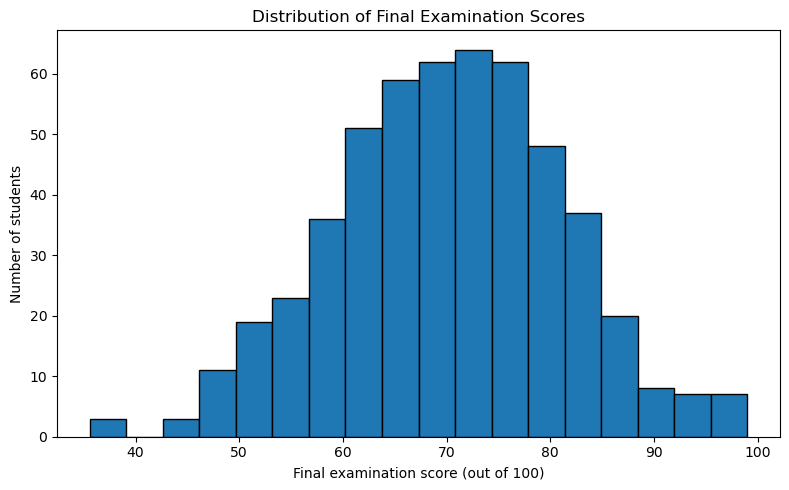

<ipython-input-8-8f22bc37cc42>:23: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(OUTPUT_DIR / "02_study_method_bar_chart.png", dpi=160)
<ipython-input-8-8f22bc37cc42>:23: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(OUTPUT_DIR / "02_study_method_bar_chart.png", dpi=160)


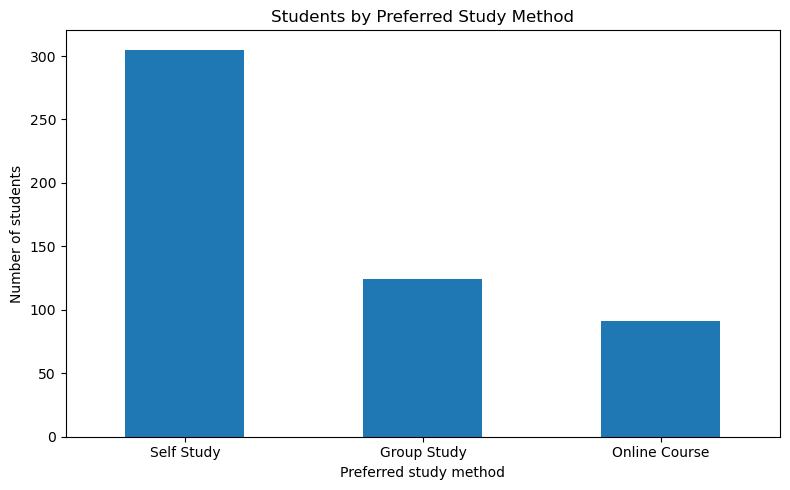

<ipython-input-8-8f22bc37cc42>:32: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(OUTPUT_DIR / "03_study_hours_vs_score.png", dpi=160)
<ipython-input-8-8f22bc37cc42>:32: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(OUTPUT_DIR / "03_study_hours_vs_score.png", dpi=160)


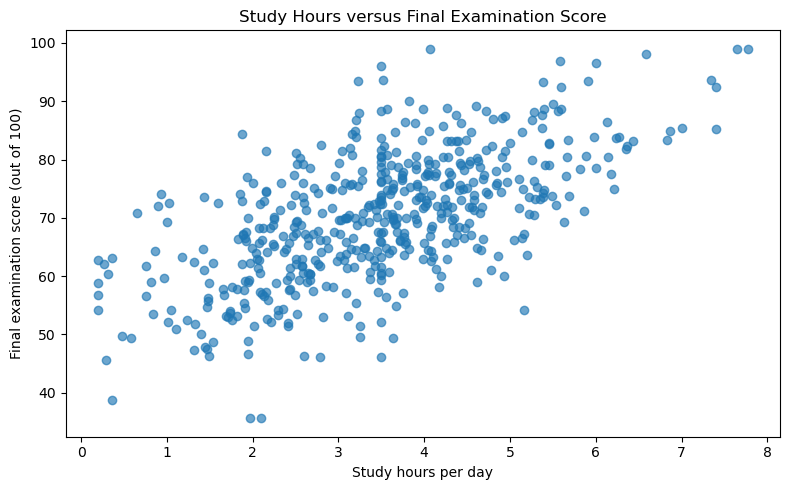

Observation 1: The histogram shows the spread and concentration of examination scores.
Observation 2: The bar chart identifies the most frequently reported study method.
Observation 3: The scatter plot allows visual inspection of the association between study time and score; it does not establish causation.


In [8]:
print("Cleaned numerical summary:")
display(clean.select_dtypes(include=np.number).describe().T)

print("\nPreferred study method frequencies:")
display(clean["preferred_study_method"].value_counts().to_frame("students"))

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(clean["final_exam_score"], bins=18, edgecolor="black")
ax.set_title("Distribution of Final Examination Scores")
ax.set_xlabel("Final examination score (out of 100)")
ax.set_ylabel("Number of students")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_exam_score_histogram.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
clean["preferred_study_method"].value_counts().plot(kind="bar", ax=ax)
ax.set_title("Students by Preferred Study Method")
ax.set_xlabel("Preferred study method")
ax.set_ylabel("Number of students")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_study_method_bar_chart.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(clean["study_hours_per_day"], clean["final_exam_score"], alpha=0.65)
ax.set_title("Study Hours versus Final Examination Score")
ax.set_xlabel("Study hours per day")
ax.set_ylabel("Final examination score (out of 100)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_study_hours_vs_score.png", dpi=160)
plt.show()

print("Observation 1: The histogram shows the spread and concentration of examination scores.")
print("Observation 2: The bar chart identifies the most frequently reported study method.")
print("Observation 3: The scatter plot allows visual inspection of the association between study time and score; it does not establish causation.")

## 11. Step 8 – Encode categorical features
All three selected categorical columns are nominal for this practical. One-hot encoding is appropriate because their categories do not represent a numerical order. The original category columns are replaced by indicator columns. The identifier and possible target are not encoded as input features.

In [9]:
id_col = "student_id"
target_col = "final_exam_score"
categorical_for_encoding = ["internet_access", "preferred_study_method", "parent_education"]
numeric_features_for_scaling = [
    "study_hours_per_day", "attendance_percentage", "sleep_hours", "assignments_completed"
]

encoded = pd.get_dummies(
    clean,
    columns=categorical_for_encoding,
    drop_first=False,
    dtype=int
)

print("Categorical columns before encoding:", categorical_for_encoding)
print("Encoded columns created:")
print([c for c in encoded.columns if any(c.startswith(prefix + "_") for prefix in categorical_for_encoding)])
display(encoded.head())
print("Shape before encoding:", clean.shape)
print("Shape after encoding:", encoded.shape)

Categorical columns before encoding: ['internet_access', 'preferred_study_method', 'parent_education']
Encoded columns created:
['internet_access_No', 'internet_access_Yes', 'preferred_study_method_Group Study', 'preferred_study_method_Online Course', 'preferred_study_method_Self Study', 'parent_education_Graduate', 'parent_education_Postgraduate', 'parent_education_School']


,student_id,study_hours_per_day,attendance_percentage,sleep_hours,assignments_completed,final_exam_score,internet_access_No,internet_access_Yes,preferred_study_method_Group Study,preferred_study_method_Online Course,preferred_study_method_Self Study,parent_education_Graduate,parent_education_Postgraduate,parent_education_School
0,STU1001,2.33,92.2,6.9,7,76.0,0,1,0,0,1,1,0,0
1,STU1002,3.72,77.9,7.9,6,66.2,0,1,0,0,1,1,0,0
2,STU1003,0.84,99.9,6.7,5,53.5,0,1,1,0,0,0,0,1
3,STU1004,5.28,84.4,6.1,10,76.4,0,1,1,0,0,0,0,1
4,STU1005,4.26,87.9,8.0,6,72.2,0,1,0,0,1,1,0,0


Shape before encoding: (520, 9)
Shape after encoding: (520, 14)


## 12. Step 9 – Scale numerical features where appropriate
Standardization is applied to the numerical input features because they use different units and ranges. The student identifier is not scaled, and the examination score is not scaled because it is the possible target. In a predictive workflow, scaling parameters must be learned on training data only; here the task is dataset preparation, so the notebook demonstrates a prepared full-dataset representation and documents this distinction.

In [10]:
scaler = StandardScaler()
encoded_scaled = encoded.copy()

encoded_scaled[numeric_features_for_scaling] = scaler.fit_transform(
    encoded_scaled[numeric_features_for_scaling]
)

print("Means after standardization (approximately 0):")
display(encoded_scaled[numeric_features_for_scaling].mean().to_frame("mean"))
print("\nStandard deviations after standardization (approximately 1):")
display(encoded_scaled[numeric_features_for_scaling].std(ddof=0).to_frame("std"))
print("\nIdentifier and target remain unchanged:")
display(encoded_scaled[[id_col, target_col]].head())

Means after standardization (approximately 0):


,mean
study_hours_per_day,-1.844678e-16
attendance_percentage,-5.653597e-16
sleep_hours,-3.791839e-16
assignments_completed,1.298107e-16



Standard deviations after standardization (approximately 1):


,std
study_hours_per_day,1.0
attendance_percentage,1.0
sleep_hours,1.0
assignments_completed,1.0



Identifier and target remain unchanged:


,student_id,final_exam_score
0,STU1001,76.0
1,STU1002,66.2
2,STU1003,53.5
3,STU1004,76.4
4,STU1005,72.2


## 13. Step 10 – Save and verify the prepared dataset
The original raw CSV is not overwritten. The final encoded and scaled dataset is saved as a separate CSV. Verify its shape, remaining missing values and duplicate count.

In [11]:
prepared_path = OUTPUT_DIR / "student_learning_habits_prepared.csv"
encoded_scaled.to_csv(prepared_path, index=False)

print("Prepared dataset saved to:", prepared_path)
print("Final shape:", encoded_scaled.shape)
print("Remaining missing values:", int(encoded_scaled.isna().sum().sum()))
print("Remaining duplicate rows:", int(encoded_scaled.duplicated().sum()))
print("\nPrepared dataset sample:")
display(encoded_scaled.head(10))

Prepared dataset saved to: outputs/student_learning_habits_prepared.csv
Final shape: (520, 14)
Remaining missing values: 0
Remaining duplicate rows: 0

Prepared dataset sample:


,student_id,study_hours_per_day,attendance_percentage,sleep_hours,assignments_completed,final_exam_score,internet_access_No,internet_access_Yes,preferred_study_method_Group Study,preferred_study_method_Online Course,preferred_study_method_Self Study,parent_education_Graduate,parent_education_Postgraduate,parent_education_School
0,STU1001,-0.817274,0.994455,-0.019405,-0.033853,76.0,0,1,0,0,1,1,0,0
1,STU1002,0.186781,-0.361885,1.054073,-0.620632,66.2,0,1,0,0,1,1,0,0
2,STU1003,-1.893564,1.724791,-0.234101,-1.207410,53.5,0,1,1,0,0,0,0,1
3,STU1004,1.313635,0.254633,-0.878187,1.726484,76.4,0,1,1,0,0,0,0,1
4,STU1005,0.576846,0.586604,1.161420,-0.620632,72.2,0,1,0,0,1,1,0,0
5,STU1006,-0.326082,0.823726,0.732029,-1.794189,69.7,1,0,1,0,0,0,1,0
6,STU1007,-0.347752,-1.386254,-0.663492,1.139705,62.6,1,0,0,0,1,1,0,0
7,STU1008,0.251792,-0.162702,-0.663492,-0.620632,79.4,0,1,0,0,1,0,1,0
8,STU1009,-0.304412,1.734276,1.268768,1.139705,81.5,1,0,0,1,0,1,0,0
9,STU1010,-0.261071,0.064935,-1.307578,-0.033853,69.9,1,0,0,0,1,1,0,0


## 14. Conclusion
The synthetic student-learning dataset was inspected and prepared without changing the original raw file. The workflow identified missing values, one impossible study-hours value, duplicate records and inconsistent category formatting. Numerical missing values were filled using medians, categorical missing values using modes, and exact duplicate rows were removed after inspection. EDA was performed with distribution, frequency and relationship plots. Nominal categorical variables were one-hot encoded, and suitable numerical input features were standardized. The possible target (`final_exam_score`) and identifier (`student_id`) were deliberately left unscaled. The final prepared CSV and supporting evidence are stored in the `outputs` folder.

### Limitations
- The records are synthetic and should not be interpreted as real student outcomes.
- Imputation can reduce variation and may introduce bias if missingness is systematic.
- A scatter plot indicates association only; it does not prove causation.
- Scaling on the complete dataset is shown only for this preparation exercise. In a later predictive model, fit the scaler on training data only to avoid data leakage.

### Submission checklist
- [x] Dataset CSV and provenance statement
- [x] Notebook with visible outputs
- [x] Dataset inspection and statistics
- [x] Missing-value report and handling
- [x] Duplicate and consistency checks
- [x] At least two visualizations
- [x] Categorical encoding
- [x] Appropriate numerical scaling
- [x] Final prepared CSV and conclusion
- [x] Public-repository README template and faculty acknowledgement